# pems08f — val diagnostics: reconstruction & generative distribution

Two evals on the **validation** residuals of `pems08f`, comparing the
**Kronecker (structured)** prior against the **isotropic** baseline. All numbers are in
raw units (**veh**) — the backbone forecast cancels, so a residual error *is* the
forecast error and we score residuals directly.

1. **Reconstruction** — fully noise the *true* val residuals to `t = T`, then run the
   deterministic reverse sampler back to `t = 0`, and report MAE / MSE.
   *Does the denoiser invert the forward process?* (Oracle-seeded — a sanity floor, not
   generative skill.)
2. **Generative distribution** — draw *pure-prior* samples (no true signal), run the
   full stochastic reverse SDE, and compare the generated residual cloud to the true val
   cloud per horizon (sliced-W1 + energy), plus sample-mean MAE/MSE and the Winkler-90
   interval + empirical coverage. *Does the model generate realistic residuals?*

> The trained denoisers live on DAIC under `results/diffusion/…`. Run this notebook where
> those checkpoints are present (or sync them down); every cell degrades cleanly with a
> message if a checkpoint is missing.

## Setup & configuration

In [7]:
import sys, pathlib
_here = pathlib.Path.cwd()
ROOT = _here if (_here / "src").exists() else _here.parent     # works from repo root or notebooks/
for _p in (str(ROOT), str(ROOT / "notebooks")):
    if _p not in sys.path:
        sys.path.insert(0, _p)
import val_eval_lib as ve

# ── config ───────────────────────────────────────────────────────────────────
DATASET = "pems08f"
SEED    = 42            # which trained seed to load (smallest available is used if absent)

# sampling settings — match scripts/eval_diffusion.py defaults; lower for a quick pass
N_STEPS       = 100     # reverse-sampler steps
RECON_WINDOWS = 1024    # val windows for eval 1 (1 trajectory each, cheap)
K             = 50      # prior samples per window for eval 2 point / interval metrics
GEN_WINDOWS   = 512     # val windows for eval 2 point / interval metrics
ETA           = 1.0     # 1.0 = full stochastic reverse SDE (proper interval dispersion)
ALPHA         = 0.1     # 0.1 -> central 90% Winkler interval
DIST_WINDOWS  = 512     # complete-case windows for the W1 / distribution comparison
DIST_SAMPLES  = 4       # prior samples per window for the W1 / distribution cloud

DEVICE = ve.pick_device()
print("device:", DEVICE)

device: mps


## Load the trained denoisers

Discovers checkpoints under `results/diffusion/**` and loads each prior; missing priors are skipped with a message.

In [8]:
runs = ve.load_runs(DATASET, device=DEVICE, seed=SEED)   # {prior: run}; skips missing checkpoints

  [kronecker] loading exp=20260612 seed=42  (/Users/serkan/Projects/research-tud/results/diffusion/20260612/pems08f/kronecker/seed42)
[eval_diffusion] schedule c_0 = 57.31 (derived from prior, θ_min=0.0872)
  [isotropic] loading exp=20260612 seed=42  (/Users/serkan/Projects/research-tud/results/diffusion/20260612/pems08f/isotropic/seed42)
[eval_diffusion] schedule c_0 = 5.00 (derived from prior, θ_min=1.0000)


## Eval 1 — Reconstruction (fully noise → denoise)

We take the true val residuals, **forward-noise them to the top of the schedule** (`t = T`,
essentially pure prior noise), then run the **deterministic** reverse sampler (`eta = 0`)
back down to `t = 0`. The reconstruction MAE/MSE (in veh) and the MAE-vs-`t` curve tell
us whether the learned reverse process actually undoes the forward noising.

In [9]:
recon = {
    prior: ve.reconstruction_eval(
        run, device=DEVICE, n_steps=N_STEPS, max_windows=RECON_WINDOWS,
        generator=ve.make_generator(DEVICE, SEED))
    for prior, run in runs.items()
}
print("done" if recon else "no checkpoints loaded — run where results/diffusion/ exists.")
(ve.reconstruction_table(recon) if recon else None)

    recon: 1024/1024 windows
    recon: 1024/1024 windows
done


,recon MAE,recon MSE,recon RMSE,val windows
Kronecker (structured),22.2152,1131.9871,33.6450,1024.0
isotropic (baseline),25.6430,1520.4117,38.9925,1024.0


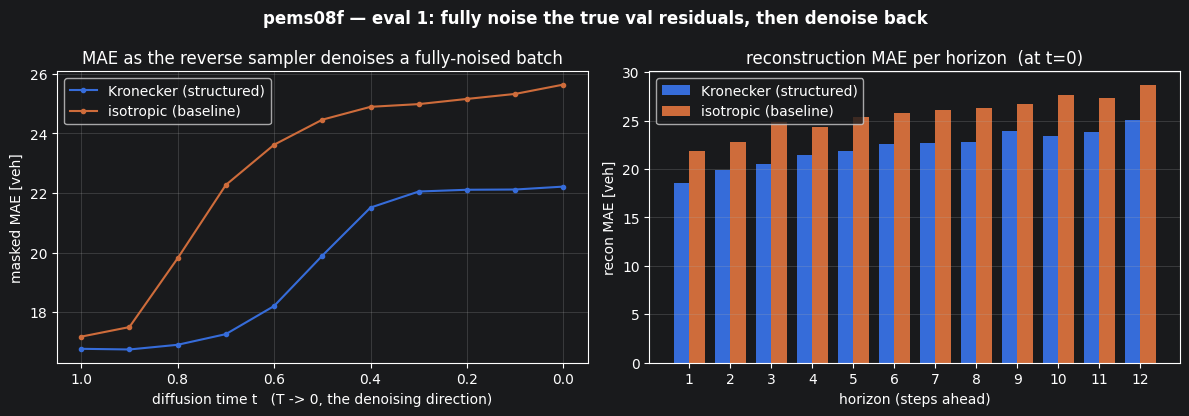

In [10]:
if recon: ve.plot_reconstruction(recon, DATASET)

**How to read it.** The left curve should fall as `t → 0`: the input starts as noise
(high MAE) and a working denoiser drives it down to a small reconstruction error. The
right bars give final per-horizon MAE — error grows with horizon (further-ahead residuals
are larger). This eval is *oracle-seeded* (it starts from the true signal's noise), so a
low MAE only confirms the reverse process is **consistent** — it's a floor, not the
model's forecasting skill. A flat/rising curve, or a recon MAE near the data scale, means
sampling is broken.

## Eval 2 — Generative distribution (prior → denoise → vs val)

Now we use **no true signal**: we draw pure-prior samples and run the **full stochastic**
reverse SDE (`eta = {ETA}`). For the highlighted horizons we overlay the generated
residual distribution on the true val distribution, and per horizon we measure
**sliced-W1 + energy distance** in node-space `R^N`. We also report the K-sample-mean
**MAE/MSE**, the **Winkler-90** interval score and **coverage** — all in veh.

In [11]:
gen = {
    prior: ve.generative_eval(
        run, device=DEVICE, k=K, n_steps=N_STEPS, eta=ETA, alpha=ALPHA,
        max_windows=GEN_WINDOWS, dist_windows=DIST_WINDOWS, dist_samples=DIST_SAMPLES,
        generator=ve.make_generator(DEVICE, SEED))
    for prior, run in runs.items()
}
print("done" if gen else "no checkpoints loaded — run where results/diffusion/ exists.")
(ve.generative_table(gen) if gen else None)

KeyboardInterrupt: 

In [ ]:
if gen: ve.plot_generative(gen, DATASET)

**How to read it.** The histograms should *match in spread and shape* (these residuals
are heavy-tailed, so watch the tails, not just the peak). **W1 / energy** (lower = better)
quantify that match in node-space `R^N`, where the structured prior's spatial correlation
should help and the isotropic baseline — which can match marginals but not the joint
spatial structure — should fall behind. **gen MAE/MSE** is point skill of the sample mean.
**Winkler-90** combines sharpness and calibration (lower = better) and must be read with
**coverage** (target ≈ 0.90): a low Winkler with coverage well below 0.90 just means the
intervals are too narrow.

### Caveats
- **One seed.** This loads `SEED`; the headline thesis numbers aggregate seeds 42 / 43 / 44.
- **Finite K.** With `K` samples the 5% / 95% quantiles (hence Winkler & coverage) are noisy — raise `K` for tighter estimates.
- **Two noise levels.** Eval 1 is deterministic (`eta = 0`, spread from prior seeds only); eval 2 is stochastic (`eta = 1`). Don't cross-compare their dispersions.
- **Val, not test.** These are validation diagnostics; the reported *test* numbers come from `scripts/eval_diffusion.py`.